## Tensors and a loop of your own

`probatum.torch.TensorEnv` hands the environment's observation, rewards and flags out as
torch tensors on a device, the card where one is visible, each the numpy path's to the bit.
A policy-gradient loop written in torch then never copies them itself. Here REINFORCE over
4,096 accounts with discrete actions, then the policy's backtest on bars it never saw.
These outputs came from the CPU.

In [1]:
import pathlib
import time

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum
import probatum.torch
import torch

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

device = "cuda" if torch.cuda.is_available() else "cpu"

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}, "
      f"torch {torch.__version__}, on {device}")

probatum 4.0.0, exchange-router 4.0.0, torch 2.15.0+cpu, on cpu


### The bars

In [2]:
PATH = pathlib.Path("../bars/bybit-linear-btcusdt-ethusdt-1h-2024-2025")

if PATH.exists():
    perp = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        perp = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=PATH)

train, test = perp["BTCUSDT"].split(when="2025-07-01")

### The environment on a device

The wrap takes the environment over, so it is stepped through the wrapper alone.

In [3]:
inner = probatum.env(train, venue="bybit_perp", window=32, actions="discrete",
                     num_envs=4_096, episode_length=24 * 14, seed=0)
env   = probatum.torch.TensorEnv(inner, device=device)

obs, _ = env.reset(seed=0)

print(f"{tuple(obs.shape)} {obs.dtype} on {obs.device}, actions {env.single_action_space}")

(4096, 168) torch.float32 on cpu, actions Discrete(3)


### The loop

Rollouts of 16 steps, each step's discounted return cut at its episode's end and
normalised, and the log-probability of each action pushed toward the returns that followed
it. Under the default autoreset the step after an episode ends ignores its action, so that
step is left out of the loss.

7,864,320 steps in 14 s, 551,787 a second with the training


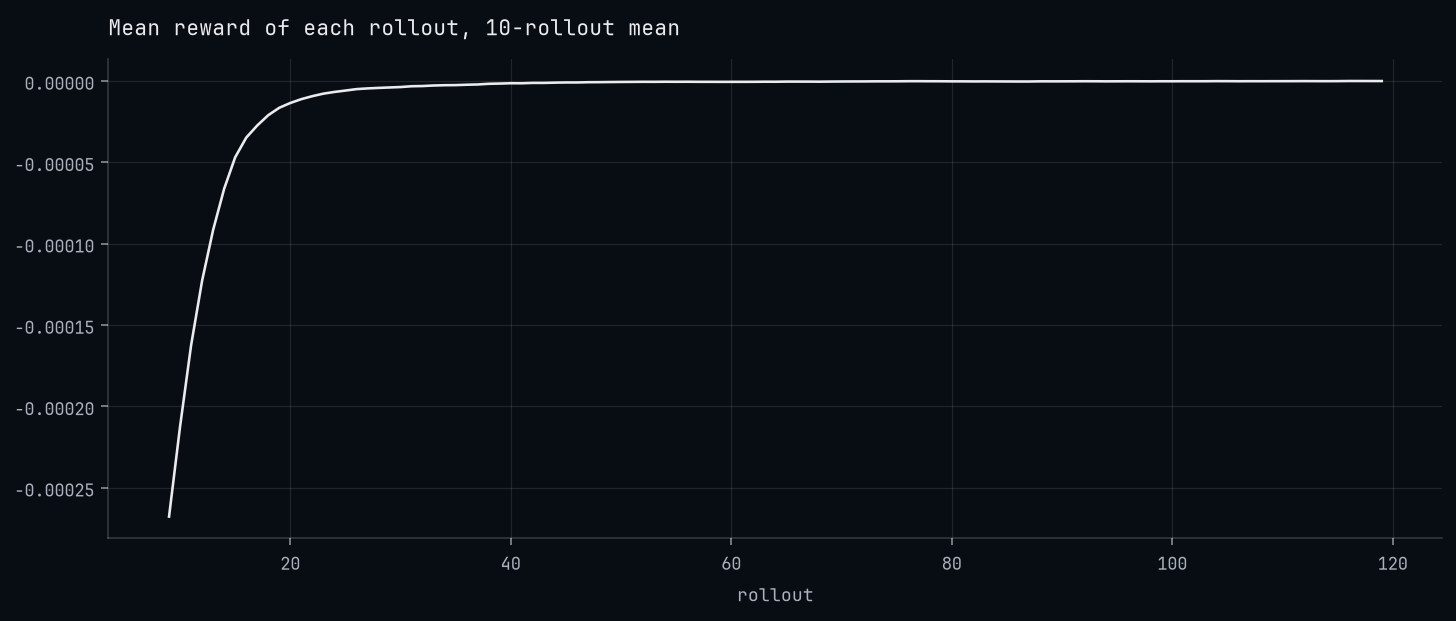

In [4]:
torch.manual_seed(0)

policy = torch.nn.Sequential(
    torch.nn.Linear(in_features=obs.shape[1], out_features=64), torch.nn.Tanh(),
    torch.nn.Linear(in_features=64, out_features=3)).to(device)

optimiser = torch.optim.Adam(params=policy.parameters(), lr=1e-3)

restarted = torch.zeros(size=(env.num_envs,), dtype=torch.bool, device=device)
means     = []

started = time.perf_counter()
for _ in range(120):
    logps, rewards, alive, kept = [], [], [], []
    for _ in range(16):
        choice  = torch.distributions.Categorical(logits=policy(obs))
        actions = choice.sample()
        obs, reward, terminated, truncated, _ = env.step(actions)
        ended   = terminated | truncated
        logps.append(choice.log_prob(actions))
        rewards.append(reward.float())
        alive.append((~ended).float())
        kept.append((~restarted).float())
        restarted = ended

    returns, running = [], torch.zeros(size=(env.num_envs,), device=device)
    for step_reward, mask in zip(reversed(rewards), reversed(alive)):
        running = step_reward + 0.99 * running * mask
        returns.insert(0, running)
    returns = torch.stack(returns)
    returns = (returns - returns.mean()) / (returns.std() + 1e-8)

    loss = -(torch.stack(logps) * returns * torch.stack(kept)).mean()
    optimiser.zero_grad()
    loss.backward()
    optimiser.step()

    means.append(torch.stack(rewards).mean().item())
elapsed = time.perf_counter() - started

print(f"{120 * 16 * env.num_envs:,} steps in {elapsed:.0f} s, "
      f"{120 * 16 * env.num_envs / elapsed:,.0f} a second with the training")

axes = pandas.Series(means).rolling(window=10).mean().plot(
    title="Mean reward of each rollout, 10-rollout mean", xlabel="rollout")
matplotlib.pyplot.show()

### The policy's backtest

A function of the observation turns the policy's logits into its action, and the spec is
the environment it trained in. Its weights at every close of the test bars, counted, then
the run they made.

In [5]:
def greedy(observation):
    with torch.no_grad():
        logits = policy(torch.as_tensor(observation, device=device))
    return logits.argmax(dim=1).cpu().numpy()


result = probatum.backtest(greedy, data=test, venue="bybit_perp", spec=inner)

print(numpy.unique(result.policy[:, 0][~numpy.isnan(result.policy[:, 0])],
                   return_counts=True))

result

(array([0.]), array([4415]))


,run,buy_and_hold,low,high,level,method,why_none
total_return_pct,0.00,-21.45,,,,,1
cagr_pct,,,,,,,2
volatility_pct,0.00,40.07,,,,,1
sharpe,,-0.99,,,,,3
max_drawdown_pct,0.00,35.89,,,,,1
exposure_pct,0.00,,,,,,
num_trades,0,,,,,,
win_rate,,,,,,,4
profit_factor,,,,,,,4
costs,0,,,,,,
